# muscat: R vs Python

Pinned source: `861683175a1804430ced420397e72fff16fe92ed`. Frozen R outputs were generated on the same inputs. The assertions below use the preregistered gates, with no threshold tuning.

In [1]:
from pathlib import Path
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd().parent
sys.path.insert(0,str(ROOT))
from pymuscat import *


## Inputs and outputs
Sum pseudobulks and explicit-design/contrast pbDS with edgeR or limma-voom. No mixed models, limma-trend, treat, DESeq2, simulation framework or automatic design inference.

       gene     logFC    AveExpr          t         p_val  p_adj.loc  \
0     ISG15  6.135464  13.633331  19.515071  2.363128e-08   0.000003   
1  AURKAIP1  0.049845  11.457255   0.147024  8.865431e-01   0.957939   
2    MRPL20  0.127681  10.586285   0.370059  7.203965e-01   0.937153   
3     SSU72 -0.254143  11.670983  -0.724948  4.879724e-01   0.779695   
4      RER1 -0.390273  11.273895  -1.030320  3.313038e-01   0.648808   

          B cluster_id contrast  p_adj.glb  
0  9.706081    B cells     stim   0.000006  
1 -7.006082    B cells     stim   0.945893  
2 -6.942731    B cells     stim   0.862447  
3 -6.735377    B cells     stim   0.683698  
4 -6.463692    B cells     stim   0.538110  
Skipped: {}


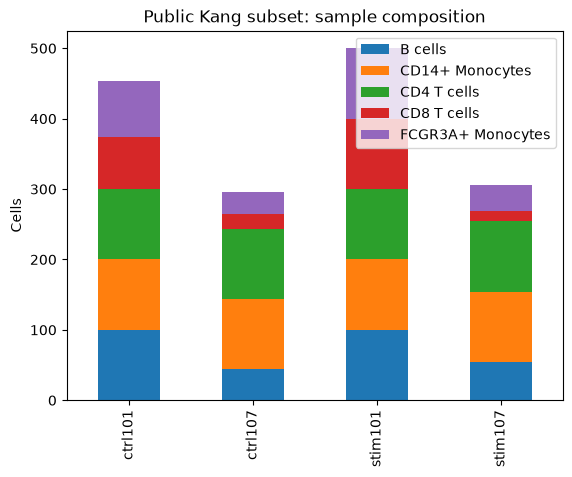

In [2]:
import anndata as ad
from scipy import sparse
counts=pd.read_csv(ROOT/'data/public_counts.csv',index_col=0)
meta=pd.read_csv(ROOT/'data/public_metadata.csv',index_col=0)
a=ad.AnnData(sparse.csr_matrix(counts.T.to_numpy()),obs=meta,var=pd.DataFrame(index=counts.index))
a.layers['counts']=a.X.copy()
pb=aggregate_data(a)
design=pd.read_csv(ROOT/'data/public_design.csv',index_col=0)
contrast=pd.read_csv(ROOT/'data/public_contrast.csv',index_col=0)
result=pb_ds(pb,design,contrast,method='limma-voom')
print(result['table'].head());print('Skipped:',result['skipped'])
pb.n_cells.T.plot.bar(stacked=True);plt.ylabel('Cells');plt.title('Public Kang subset: sample composition');plt.show()


## Numerical verdict
The tests compare every covered output and list failures if any. Regenerate the R outputs using the README command when independently auditing.

In [3]:
import subprocess
r=subprocess.run([sys.executable,'-m','pytest','-q'],cwd=ROOT,capture_output=True,text=True)
print(r.stdout)
assert r.returncode==0,r.stderr+r.stdout

......                                                                   [100%]
6 passed in 1.20s



## Limits
A passing fixture is not a biological accuracy benchmark or a claim to cover unported exports.